# 03 · CNN preentrenada con salida monótona

**Punto de partida (notebook 02):** el baseline de textura da un EMD de 44 en LOSO, pero entre cámaras sube a 53–70, y en el leaderboard público sacó 64,9. El problema principal es la **generalización a otra cámara**, no la capacidad del modelo.

**Enfoque:** con 24 muestras, afinar una CNN entera sobreajustaría. En su lugar:

1. Una **CNN preentrenada y congelada** (ConvNeXt-Tiny, ImageNet-22k) convierte cada recorte de 224×224 px (≈ 50×50 mm a 4,5 px/mm) en un vector de 768 features.
2. Encima se entrenan modelos pequeños: **Ridge** sobre la media por foto, y una **cabeza monótona** (softmax de incrementos + suma acumulada) entrenada directamente con la **EMD** como pérdida.
3. Cada modelo se prueba **en color y en escala de grises**, porque el color es lo que más cambia entre cámaras.

**Criterio de selección:** el EMD medio **entre cámaras**, no el LOSO normal. Es el escenario que reproduce el test, que es todo iPhone, y el notebook 02 mostró que es el que predice la puntuación real.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from soilgrain.data import load_labels, load_photo, photo_index
from soilgrain.embeddings import load_backbone, patch_embeddings
from soilgrain.features import TARGET_PPM
from soilgrain.gradation import soil_class
from soilgrain.metrics import SIEVES, emd, make_valid
from soilgrain.model import MonotoneHead, emd_loss
from soilgrain.plotting import CLASS_COLOR, CLASSES, GRID, INK, INK_2, set_style

warnings.filterwarnings("ignore", category=UserWarning)
set_style()
FIG = ROOT / "reports" / "figures"
PROCESSED = ROOT / "data" / "processed"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

labels = load_labels()
sample_ids = labels.index.values
classes = pd.Series([soil_class(SIEVES, r) for r in labels.values], index=labels.index)
photos = photo_index()
train_mask = (photos["split"] == "train").values

Dispositivo: cuda NVIDIA GeForce RTX 3060 Ti


## 1. Embeddings de la CNN congelada

In [2]:
BACKBONE = "convnext_tiny.fb_in22k"
patch_emb = {}
for mode in ("color", "gris"):
    cache = PROCESSED / f"emb_{BACKBONE.split('.')[0]}_{mode}_ppm{TARGET_PPM}.npz"
    if cache.exists():
        z = np.load(cache)
        patch_emb[mode] = [z[str(i)] for i in range(len(photos))]
        continue
    backbone = load_backbone(BACKBONE)
    patch_emb[mode] = [patch_embeddings(load_photo(p.path, TARGET_PPM, p.ppm), backbone, gray=mode == "gris")
                       for p in photos.itertuples()]
    np.savez_compressed(cache, **{str(i): e for i, e in enumerate(patch_emb[mode])})
photo_emb = {m: np.stack([e.mean(axis=0) for e in v]) for m, v in patch_emb.items()}
n_patches = [len(e) for e in patch_emb["color"]]
print(f"{len(photos)} fotos · {sum(n_patches)} recortes · {photo_emb['color'].shape[1]} features por recorte")

162 fotos · 13241 recortes · 768 features por recorte


## 2. Validación

La misma función sirve para el LOSO normal y para el cambio de cámara: para cada muestra se entrena con las demás (filtrando opcionalmente por cámara) y se predice con sus fotos (filtrando opcionalmente por la otra cámara). La predicción de la muestra es la media de las curvas de sus fotos.

In [3]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

TARGET_COLS = labels.columns[:-1]
photo_y = labels.reindex(photos["sample_id"]).values  # NaN en las fotos de test
moto = (photos["phone"].str.startswith("Motorola")).values
sams = (photos["phone"] == "Samsung A52").values
ALL = np.ones(len(photos), bool)

SETUPS = {
    "LOSO (todas las cámaras)": (ALL, ALL),
    "Motorola → Samsung": (moto, sams),
    "Samsung → Motorola": (sams, moto),
}

def validate(fit_predict, train_filter=ALL, eval_filter=ALL):
    preds = {}
    for sid in sample_ids:
        is_sid = (photos["sample_id"] == sid).values
        tr = np.where(train_mask & ~is_sid & train_filter)[0]
        ev = np.where(is_sid & eval_filter)[0]
        if len(ev):
            preds[sid] = fit_predict(tr, ev)
    preds = pd.DataFrame(make_valid(np.vstack(list(preds.values()))), index=list(preds), columns=labels.columns)
    return pd.Series(emd(labels.loc[preds.index].values, preds.values), index=preds.index), preds

def ridge_on(X):
    def fit_predict(tr, ev):
        model = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": np.logspace(0, 5, 11)},
                             cv=GroupKFold(n_splits=5), scoring="neg_mean_absolute_error")
        model.fit(X[tr], photo_y[tr][:, :-1], groups=photos["sample_id"].values[tr])
        return np.r_[model.predict(X[ev]).mean(axis=0), 100]
    return fit_predict

### Cabeza monótona entrenada con EMD

Se entrena sobre **recortes** (miles de filas en lugar de 127 fotos), con la etiqueta de su muestra. Cada muestra pesa lo mismo en la pérdida, tenga 3 u 8 fotos. La salida es una curva válida por construcción, así que no necesita post-proceso, y se optimiza exactamente la métrica de la competición.

In [4]:
def head_on(mode, epochs=40, seeds=3, hidden=128, lr=1e-3, wd=1e-2):
    def fit_predict(tr, ev):
        Xtr = np.concatenate([patch_emb[mode][i] for i in tr])
        ytr = np.concatenate([np.repeat(photo_y[i][None], n_patches[i], 0) for i in tr])
        sid_tr = np.concatenate([[photos["sample_id"].iat[i]] * n_patches[i] for i in tr])
        w = pd.Series(sid_tr).map(1 / pd.Series(sid_tr).value_counts()).values
        mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
        Xev = np.concatenate([patch_emb[mode][i] for i in ev])
        to_t = lambda a: torch.tensor(a, dtype=torch.float32, device=DEVICE)
        Xtr_t, ytr_t, w_t, Xev_t = to_t((Xtr - mu) / sd), to_t(ytr), to_t(w / w.mean()), to_t((Xev - mu) / sd)
        curves = []
        for seed in range(seeds):
            torch.manual_seed(seed)
            head = MonotoneHead(Xtr.shape[1], hidden=hidden).to(DEVICE)
            opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=wd)
            for _ in range(epochs):
                for idx in torch.randperm(len(Xtr_t), device=DEVICE).split(256):
                    pred = head(Xtr_t[idx])
                    loss = (emd_loss(pred, ytr_t[idx], reduce=False) * w_t[idx]).mean()
                    opt.zero_grad(); loss.backward(); opt.step()
            head.eval()
            with torch.no_grad():
                curves.append(head(Xev_t).mean(0).cpu().numpy())
        return np.mean(curves, axis=0)
    return fit_predict

### Referencia: el baseline de textura (notebook 02)

Lo recalculo aquí con las features en caché para compararlo en igualdad de condiciones y para poder combinarlo con la CNN.

In [5]:
tex = pd.read_csv(PROCESSED / f"features_ppm{TARGET_PPM}.csv").set_index("file").loc[photos["path"].map(lambda p: p.name)]
CAMERA_SENSITIVE = ("lum_mean", "lum_std", "lum_p10", "lum_p90", "chroma_r", "chroma_g")
X_tex = tex[[c for c in tex.columns if c != "n_patches" and not c.startswith(CAMERA_SENSITIVE)]].values

def ensemble(*fps):
    return lambda tr, ev: np.mean([fp(tr, ev) for fp in fps], axis=0)

MODELS = {
    "Textura · Ridge (baseline 02)": ridge_on(X_tex),
    "CNN color · Ridge": ridge_on(photo_emb["color"]),
    "CNN gris · Ridge": ridge_on(photo_emb["gris"]),
    "CNN color · cabeza EMD": head_on("color"),
    "CNN gris · cabeza EMD": head_on("gris"),
}

In [6]:
scores, oof = {}, {}
for name, fp in MODELS.items():
    for setup, (trf, evf) in SETUPS.items():
        s, p = validate(fp, trf, evf)
        scores[(name, setup)] = s
        if setup.startswith("LOSO"):
            oof[name] = p
table = pd.Series({k: v.mean() for k, v in scores.items()}).unstack()[list(SETUPS)]
table["Media entre cámaras"] = table[["Motorola → Samsung", "Samsung → Motorola"]].mean(axis=1)
table.round(1).sort_values("Media entre cámaras")

,LOSO (todas las cámaras),Motorola → Samsung,Samsung → Motorola,Media entre cámaras
CNN color · cabeza EMD,46.7,42.7,42.0,42.3
CNN gris · cabeza EMD,45.2,44.3,42.3,43.3
CNN gris · Ridge,41.7,47.8,48.6,48.2
CNN color · Ridge,40.9,51.8,45.7,48.8
Textura · Ridge (baseline 02),44.2,70.2,53.2,61.7


### Combinación

Si la CNN y la textura se equivocan en muestras distintas, promediar sus curvas debería reducir el error. Pruebo a combinar el mejor modelo CNN entre cámaras con el baseline de textura.

In [7]:
best_cnn = table.drop(index="Textura · Ridge (baseline 02)")["Media entre cámaras"].idxmin()
ens_name = f"Media: {best_cnn} + textura"
MODELS[ens_name] = ensemble(MODELS[best_cnn], MODELS["Textura · Ridge (baseline 02)"])
for setup, (trf, evf) in SETUPS.items():
    s, p = validate(MODELS[ens_name], trf, evf)
    scores[(ens_name, setup)] = s
    if setup.startswith("LOSO"):
        oof[ens_name] = p
table = pd.Series({k: v.mean() for k, v in scores.items()}).unstack()[list(SETUPS)]
table["Media entre cámaras"] = table[["Motorola → Samsung", "Samsung → Motorola"]].mean(axis=1)
table = table.sort_values("Media entre cámaras")
table.round(1)

,LOSO (todas las cámaras),Motorola → Samsung,Samsung → Motorola,Media entre cámaras
CNN color · cabeza EMD,46.7,42.7,42.0,42.3
CNN gris · cabeza EMD,45.2,44.3,42.3,43.3
CNN gris · Ridge,41.7,47.8,48.6,48.2
CNN color · Ridge,40.9,51.8,45.7,48.8
Media: CNN color · cabeza EMD + textura,43.6,52.9,46.6,49.7
Textura · Ridge (baseline 02),44.2,70.2,53.2,61.7


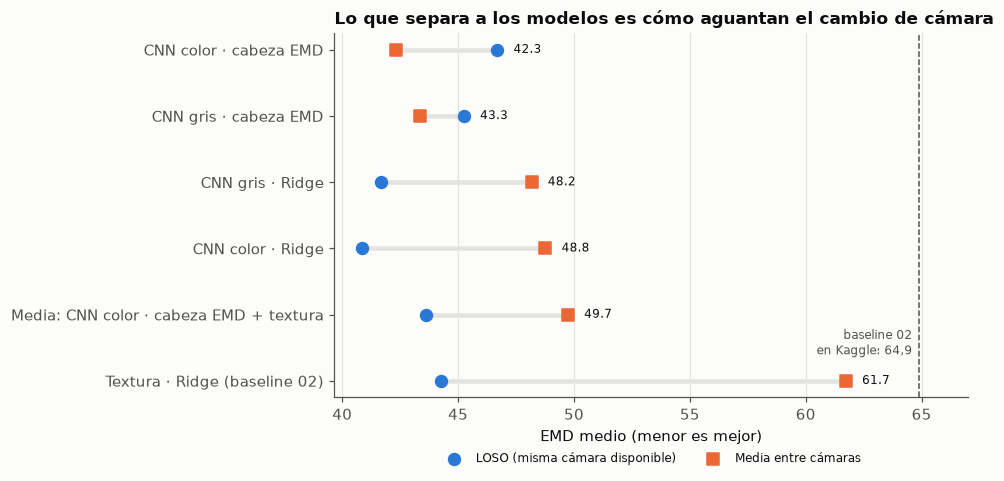

In [8]:
fig, ax = plt.subplots(figsize=(9, 0.55 * len(table) + 1.2))
y = np.arange(len(table))
ax.scatter(table["LOSO (todas las cámaras)"], y, s=60, color="#2a78d6", label="LOSO (misma cámara disponible)", zorder=3)
ax.scatter(table["Media entre cámaras"], y, s=60, color="#eb6834", marker="s", label="Media entre cámaras", zorder=3)
for i, (a, b) in enumerate(zip(table["LOSO (todas las cámaras)"], table["Media entre cámaras"])):
    ax.plot([a, b], [i, i], color=GRID, lw=3, zorder=1)
    ax.text(max(a, b) + 0.7, i, f"{b:.1f}", va="center", fontsize=8, color=INK)
ax.axvline(64.9, color=INK_2, ls="--", lw=1)
ax.text(64.6, len(table) - 1.4, "baseline 02\nen Kaggle: 64,9", fontsize=8, color=INK_2, ha="right")
ax.set_yticks(y, table.index)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("EMD medio (menor es mejor)")
ax.set_xlim(right=67)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title("Lo que separa a los modelos es cómo aguantan el cambio de cámara", loc="left")
fig.tight_layout()
fig.savefig(FIG / "10_cnn_vs_baseline.png", dpi=150, bbox_inches="tight")

## 3. Error por clase del modelo elegido

In [9]:
chosen = table["Media entre cámaras"].idxmin()
print("Modelo elegido:", chosen)
by_class = pd.DataFrame({
    setup: scores[(chosen, setup)].groupby(classes).mean() for setup in SETUPS
}).reindex(CLASSES)
by_class.round(1)

Modelo elegido: CNN color · cabeza EMD


,LOSO (todas las cámaras),Motorola → Samsung,Samsung → Motorola
finos,62.1,52.4,32.4
arena,54.4,48.5,55.8
grava,34.5,32.9,41.8


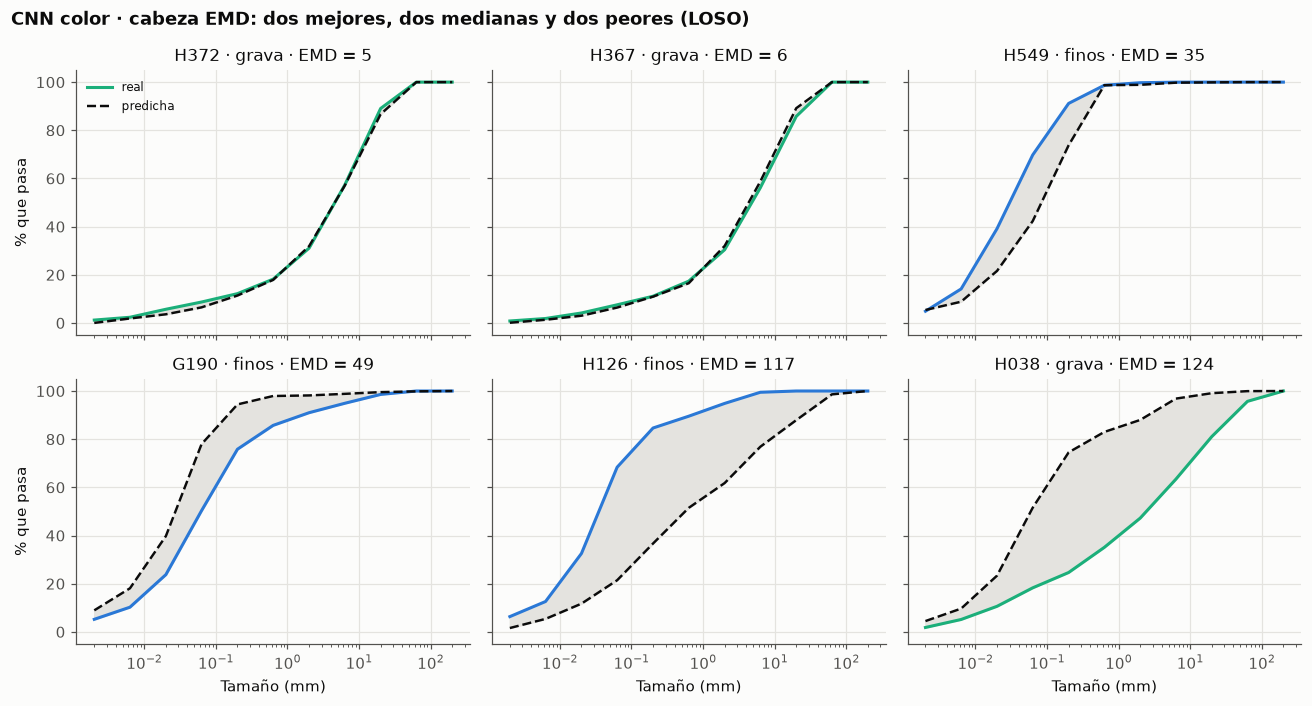

In [10]:
res = scores[(chosen, "LOSO (todas las cámaras)")].sort_values()
show = list(res.index[:2]) + list(res.index[len(res) // 2 - 1:len(res) // 2 + 1]) + list(res.index[-2:])
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True)
for ax, sid in zip(axes.flat, show):
    cls = classes[sid]
    ax.fill_between(SIEVES, labels.loc[sid], oof[chosen].loc[sid], color=GRID, zorder=1)
    ax.plot(SIEVES, labels.loc[sid], color=CLASS_COLOR[cls], label="real", zorder=3)
    ax.plot(SIEVES, oof[chosen].loc[sid], color=INK, ls="--", lw=1.6, label="predicha", zorder=3)
    ax.set_xscale("log")
    ax.set_title(f"{sid} · {cls} · EMD = {res[sid]:.0f}", fontweight="normal")
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("% que pasa")
for ax in axes[-1]:
    ax.set_xlabel("Tamaño (mm)")
fig.suptitle(f"{chosen}: dos mejores, dos medianas y dos peores (LOSO)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "11_curvas_cnn.png", dpi=150, bbox_inches="tight")

## 4. Envío

In [11]:
train_idx = np.where(train_mask)[0]
test_photos = photos[~train_mask]
template = pd.read_csv(ROOT / "data" / "raw" / "sample_submission.csv")
rows = {sid: MODELS[chosen](train_idx, np.where((photos["sample_id"] == sid).values)[0])
        for sid in template["sample_id"]}
sub = pd.DataFrame(make_valid(np.vstack(list(rows.values()))), index=list(rows), columns=template.columns[1:])
out = ROOT / "submissions" / "cnn.csv"
sub.round(4).to_csv(out, index_label="sample_id")
assert (np.diff(sub.values, axis=1) >= 0).all() and (sub.values[:, -1] == 100).all()
print("Guardado en", out.relative_to(ROOT))
sub.round(1)

Guardado en submissions/cnn.csv


,0.002,0.0063,0.02,0.063,0.2,0.63,2,6.3,20,63,200
HPC_Airbus BS6-3,1.2,2.5,9.8,49.099998,94.699997,99.000000,99.099998,99.699997,99.900002,100.000000,100.0
HPC_Audorfring,0.6,3.3,7.7,24.299999,55.500000,74.300003,78.400002,86.900002,93.400002,99.300003,100.0
HPC_Muenster_BS6_9_0-10m,0.6,4.1,6.8,14.700000,25.900000,33.000000,44.299999,61.000000,81.099998,96.599998,100.0
HPC_Airbus BS10-4bis7,0.8,1.8,7.8,48.000000,95.900002,99.800003,99.900002,100.000000,100.000000,100.000000,100.0
HPC_Airbus BS12-5bis8,1.0,2.4,8.9,47.299999,94.099998,99.699997,99.800003,99.900002,100.000000,100.000000,100.0
HPC_Kleinkummerfeld 2-2,1.9,3.6,12.4,39.900002,81.599998,93.699997,95.400002,99.199997,99.599998,100.000000,100.0
HPC_Kleinkummerfeld 2-3,2.3,3.6,13.8,45.599998,90.900002,98.500000,98.900002,99.900002,100.000000,100.000000,100.0
HPC_Kleinkummerfeld 9-4,1.5,2.7,10.7,48.500000,93.599998,98.599998,98.900002,99.900002,99.900002,100.000000,100.0
HPC_Kleinkummerfeld 18-3,1.9,3.0,11.8,50.500000,95.199997,99.699997,99.699997,100.000000,100.000000,100.000000,100.0
HPC_Testfeld Lidl WHV,0.5,3.8,6.5,13.300000,23.700001,30.100000,40.500000,58.900002,81.300003,95.199997,100.0


## Conclusiones

1. **La CNN congelada generaliza mucho mejor entre cámaras que la textura hecha a mano.** El mejor modelo pasa de un EMD de 61,7 a 42,3 entre cámaras. Los vectores de una red preentrenada en millones de imágenes describen *formas* de grano que cambian poco con el sensor.
2. **Entrenar con la métrica correcta importa más que el modelo encima.** Ridge sobre las mismas features gana en el LOSO normal (40,9), pero se degrada al cambiar de cámara (48,8). La cabeza monótona entrenada con EMD queda casi igual (46,7 frente a 42,3). Además, produce curvas válidas sin post-proceso.
3. **El gris no aporta más aquí.** Con la cabeza EMD, color y gris quedan parecidos entre cámaras: la CNN ya depende poco del color. Me quedo con el color.
4. **Combinar con la textura empeora**, porque la textura arrastra su sensibilidad a la cámara.
5. **Los errores grandes se repiten en las mismas muestras** (H038 y H126, igual que en el baseline). Son los casos del EDA en que la superficie fotografiada no representa la muestra tamizada. Ningún modelo de imagen los va a resolver; harían falta más muestras o información adicional.

**Cautela:** entre seis variantes he elegido la que mejor sale entre cámaras, así que el 42,3 es algo optimista. Los hiperparámetros de la cabeza (40 épocas, 128 neuronas ocultas, dropout 0,3) no se han ajustado, para no sobreajustar a 24 muestras.